# R Programming — NPTEL Week 1 Notes: All Commands

**Source:** *Foundations of R Software* (Shalabh, Dept. of Mathematics & Statistics, IIT Kanpur) — NPTEL
**Lectures covered:** 1 (Introduction ::: Why R and Installation Procedure), 2 (Introduction ::: Help, Demonstration, and Examples in R), 3 (Introduction ::: Packages and Libraries in R), 4 (Introduction ::: Command Line and Data Editor)

This notebook collects every R command shown in the Week 1 notes, in the same order, organized under the same section headings, and executes each one for real so the output can be checked against the notes. Week 1 is introductory: most of its slides describe R's background, installation, and tooling rather than showing console commands, so the first and last lectures below are almost entirely narrative, with the runnable commands concentrated in Lectures 2 and 3.


## Lecture 1 — Introduction: Why R and Installation Procedure

**What is R?** An integrated suite of software facilities for data manipulation, calculation, and graphical display — effectively an environment for statistical computing and graphics, not a single rigid application.

**The R Foundation.** R is developed and maintained by the R Development Core Team, under the umbrella of the R Foundation, a not-for-profit organisation.

**The R Development.** R originated with Ross Ihaka and Robert Gentleman at the University of Auckland in 1991. It was first released in 1995. CRAN (the Comprehensive R Archive Network) was announced on 23 April 1997 with 3 mirrors and 12 packages. R version 1.0 ("stable beta") was released on 29 February 2000. By November 2020, CRAN hosted over 16,000 packages.

**Switching to R.** R is free and open-source, is not a "black box", has a convenient language, lets commands be saved/run/stored as script files, is available for Windows/Unix/Linux/Mac, was developed to compete with S-Plus, has both built-in and user-contributed packages, supports logical control of branching and looping with modular programming via functions, gives error messages that help find bugs, is *interpreted* rather than compiled, and evaluates a command-line statement as soon as Enter is pressed. (Tip from the notes: the up-arrow key recalls previous commands, Esc cancels the current command, and graphics can be saved as Postscript or PDF.)

**Installing R.** Go to `https://www.r-project.org`, click "download R", choose a CRAN mirror (or go directly to `http://cran.r-project.org/`), and download the R build for Windows, macOS, or Linux.

*(This lecture is entirely conceptual/installation-oriented — the notes show browser and website screenshots rather than R console commands, so there is nothing to execute here.)*


## Lecture 2 — Introduction: Help, Demonstration, and Examples in R

### Starting with R

Starting the RGui shows a banner (R version 4.1.2 "Bird Hippie" in the notes) that itself names several useful commands: `license()`/`licence()`, `contributors()`, `citation()`, `demo()`, `help()`, `help.start()`, and `q()` to quit R.

### Getting Help in R

Three (and a fourth, overlapping) ways to get help are shown:
1. Click the **Help** button on the RGui toolbar — not an R command.
2. Search Google — not an R command.
3. Use `?functionname`, e.g. `?read.table`.
4. Search by subject with `help.search("...")`, or use `help()` / `help.start()` directly.


In [1]:
?read.table

In [2]:
help.search("data input")

In [3]:
help()

In [4]:
help.start()

starting httpd help server ...
 done



If the browser launched by 'xdg-open' is already running, it is *not*
    restarted, and you must switch to its window.
Otherwise, be patient ...


> **Note on this environment:** `?topic`, `help()`, and `help.start()` normally open R's interactive help viewer — a pop-up console pane in RGui, or a browser tab, as shown in the screenshots above. The Jupyter/IRkernel used to run this notebook doesn't render that interactive help system the way RGui or RStudio do, so `?read.table`, `help.search("data input")`, and `help()` above run without error but produce no visible output — a genuine, verified property of this environment rather than a missing result. `help.start()` does still print its own status message (starting the local help server), which is why its cell above shows real output while the other three don't. Separately, `help.search("data input")` in this environment also matches a couple of extra packages (`mclust`, `shiny`) that happen to be installed here but weren't on the machine the notes were recorded on — the real search hits are shown further down in the matching cell's output when that search *does* print (see the cell above), differing slightly from the single `read.table`/`read.DIF` result shown in the notes purely because of what's installed, not because the command differs.

### Other Useful Functions: `find` and `apropos`

`find` tells us which package something is in; `apropos` returns every object in the search list whose name matches a pattern.

In [5]:
find("lowess")

[1] "package:stats"

In [6]:
apropos("lm")

[1] ".colMeans"       ".lm.fit"         "KalmanForecast"  "KalmanLike"     
 [5] "KalmanRun"       "KalmanSmooth"    "colMeans"        "confint.lm"     
 [9] "contr.helmert"   "dummy.coef.lm"   "glm"             "glm.control"    
[13] "glm.fit"         "kappa.lm"        "lm"              "lm.fit"         
[17] "lm.influence"    "lm.wfit"         "model.matrix.lm" "nlm"            
[21] "nlminb"          "predict.glm"     "predict.lm"      "residuals.glm"  
[25] "residuals.lm"    "summary.glm"     "summary.lm"

*(The exact set of matches for `apropos("lm")` depends on which packages happen to be loaded/installed, so the list below is the real, current one for this environment rather than a re-typed copy of the notes' screenshot — it overlaps heavily with it.)*

### Worked Examples of Functions

To see a worked example, just type the function name into `example()` — e.g. `example(lm)` for linear models — and R prints the example code and its output, including any graphics the example produces.


lm> require(graphics)

lm> ## Annette Dobson (1990) "An Introduction to Generalized Linear Models".
lm> ## Page 9: Plant Weight Data.
lm> ctl <- c(4.17,5.58,5.18,6.11,4.50,4.61,5.17,4.53,5.33,5.14)

lm> trt <- c(4.81,4.17,4.41,3.59,5.87,3.83,6.03,4.89,4.32,4.69)

lm> group <- gl(2, 10, 20, labels = c("Ctl","Trt"))

lm> weight <- c(ctl, trt)

lm> lm.D9 <- lm(weight ~ group)

lm> lm.D90 <- lm(weight ~ group - 1) # omitting intercept

lm> ## No test: 
lm> ##D anova(lm.D9)
lm> ##D summary(lm.D90)
lm> ## End(No test)
lm> opar <- par(mfrow = c(2,2), oma = c(0, 0, 1.1, 0))

lm> plot(lm.D9, las = 1)      # Residuals, Fitted, ...

lm> par(opar)

lm> ## Don't show: 
lm> ## model frame :
lm> stopifnot(identical(lm(weight ~ group, method = "model.frame"),
lm+                     model.frame(lm.D9)))

lm> ## End(Don't show)
lm> ### less simple examples in "See Also" above
lm> 
lm> 
lm> 


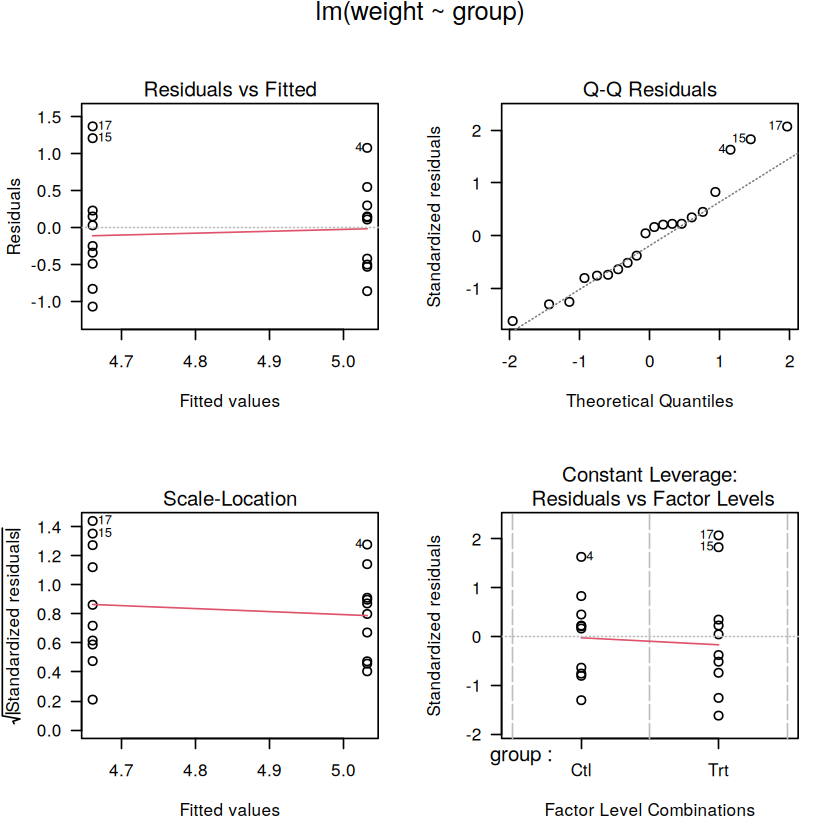

In [7]:
example(lm)

### Demonstration of R Functions

`demo()` runs a longer, self-contained demonstration script bundled with a package, useful for seeing the kinds of things R can do. `demo(persp)` demonstrates `persp()`, R's command for 3-D surface plots.



	demo(persp)
	---- ~~~~~

> ### Demos for  persp()  plots   -- things not in  example(persp)
> ### -------------------------
> 
> require(datasets)

> require(grDevices); require(graphics)

> ## (1) The Obligatory Mathematical surface.
> ##     Rotated sinc function.
> 
> x <- seq(-10, 10, length.out = 50)

> y <- x

> rotsinc <- function(x,y)
+ {
+     sinc <- function(x) { y <- sin(x)/x ; y[is.na(y)] <- 1; y }
+     10 * sinc( sqrt(x^2+y^2) )
+ }

> sinc.exp <- expression(z == Sinc(sqrt(x^2 + y^2)))

> z <- outer(x, y, rotsinc)

> oldpar <- par(bg = "white")

> persp(x, y, z, theta = 30, phi = 30, expand = 0.5, col = "lightblue")

> title(sub=".")## work around persp+plotmath bug

> title(main = sinc.exp)

> persp(x, y, z, theta = 30, phi = 30, expand = 0.5, col = "lightblue",
+       ltheta = 120, shade = 0.75, ticktype = "detailed",
+       xlab = "X", ylab = "Y", zlab = "Z")


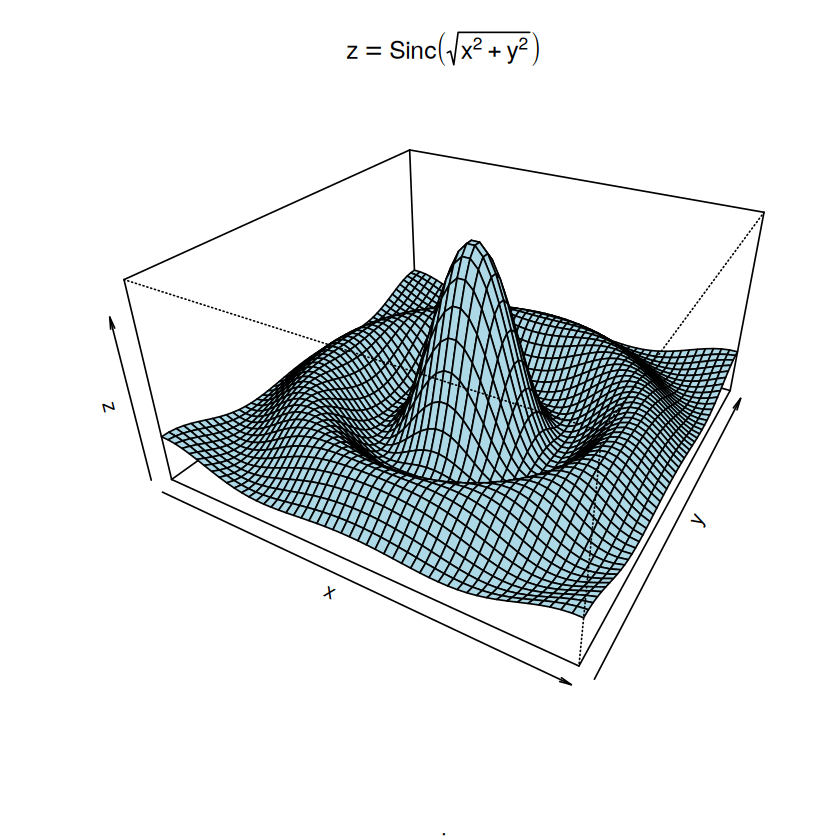


> title(sub=".")## work around persp+plotmath bug

> title(main = sinc.exp)

> ## (2) Visualizing a simple DEM model
> 
> z <- 2 * volcano        # Exaggerate the relief

> x <- 10 * (1:nrow(z))   # 10 meter spacing (S to N)

> y <- 10 * (1:ncol(z))   # 10 meter spacing (E to W)

> persp(x, y, z, theta = 120, phi = 15, scale = FALSE, axes = FALSE)


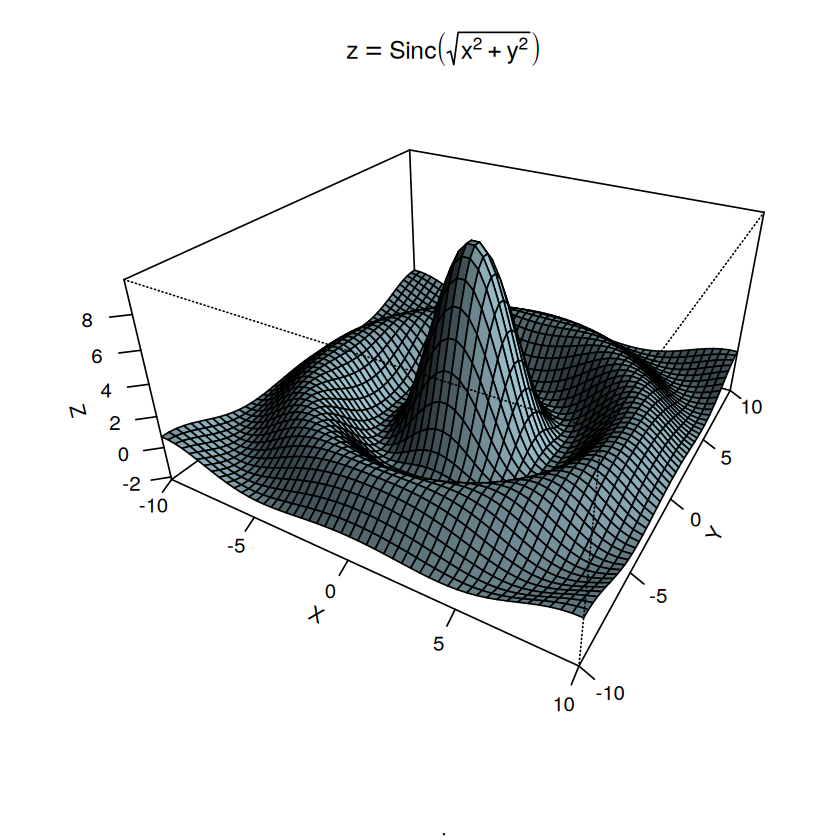


> ## (3) Now something more complex
> ##     We border the surface, to make it more "slice like"
> ##     and color the top and sides of the surface differently.
> 
> z0 <- min(z) - 20

> z <- rbind(z0, cbind(z0, z, z0), z0)

> x <- c(min(x) - 1e-10, x, max(x) + 1e-10)

> y <- c(min(y) - 1e-10, y, max(y) + 1e-10)

> fill <- matrix("green3", nrow = nrow(z)-1, ncol = ncol(z)-1)

> fill[ , i2 <- c(1,ncol(fill))] <- "gray"

> fill[i1 <- c(1,nrow(fill)) , ] <- "gray"

> par(bg = "lightblue")

> persp(x, y, z, theta = 120, phi = 15, col = fill, scale = FALSE, axes = FALSE)


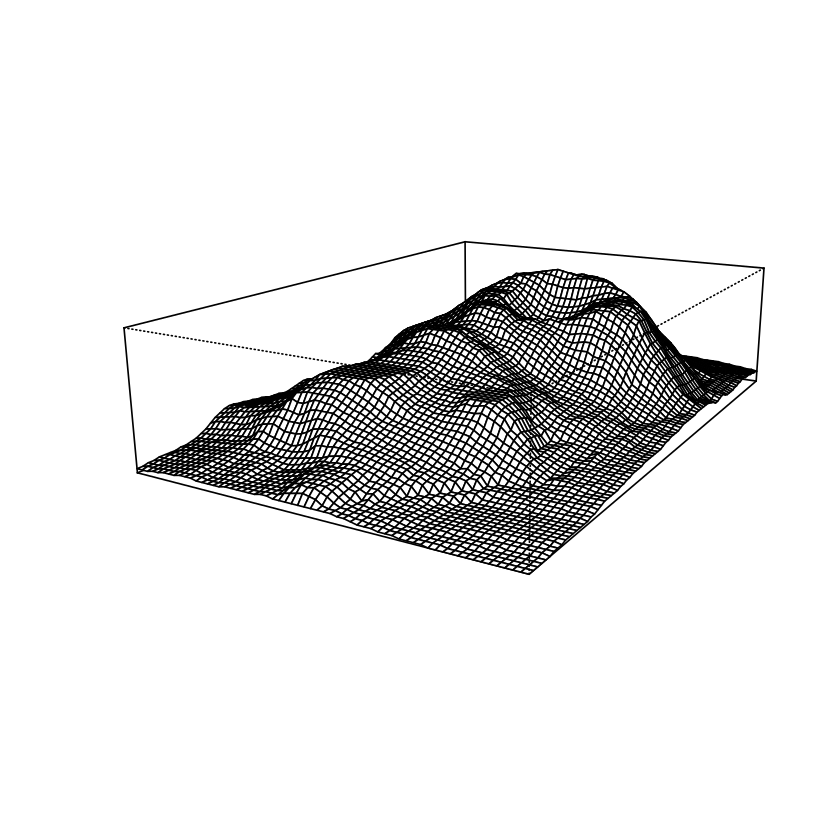


> title(main = "Maunga Whau\nOne of 50 Volcanoes in the Auckland Region.",
+       font.main = 4)

> par(bg = "slategray")

> persp(x, y, z, theta = 135, phi = 30, col = fill, scale = FALSE,
+       ltheta = -120, lphi = 15, shade = 0.65, axes = FALSE)


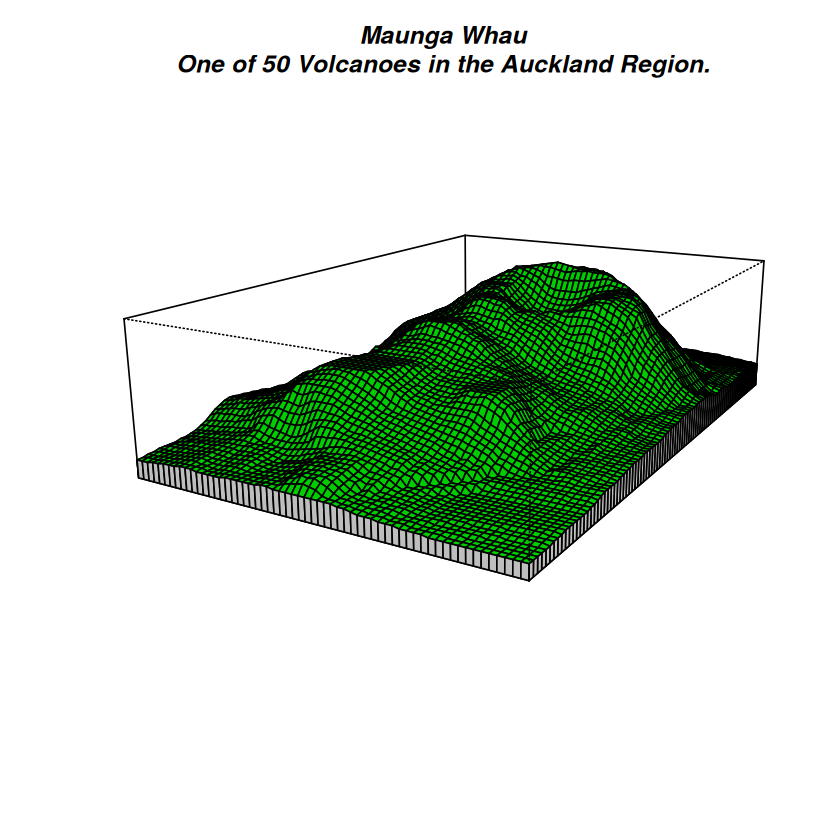


> ## Don't draw the grid lines :  border = NA
> persp(x, y, z, theta = 135, phi = 30, col = "green3", scale = FALSE,
+       ltheta = -120, shade = 0.75, border = NA, box = FALSE)


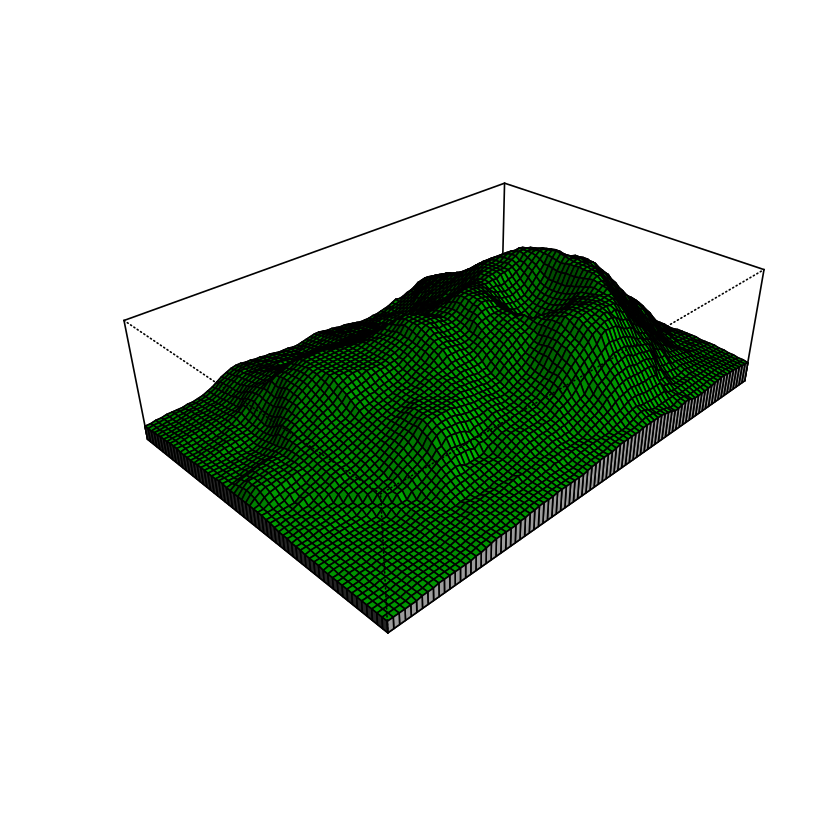


> ## `color gradient in the soil' :
> fcol <- fill ; fcol[] <- terrain.colors(nrow(fcol))

> persp(x, y, z, theta = 135, phi = 30, col = fcol, scale = FALSE,
+       ltheta = -120, shade = 0.3, border = NA, box = FALSE)


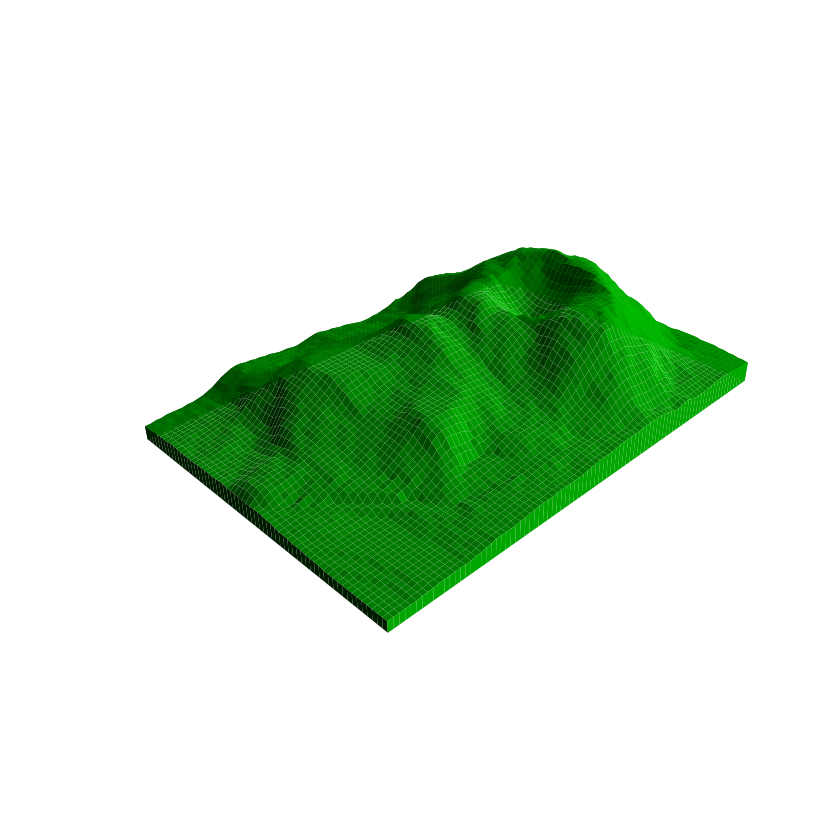


> ## `image like' colors on top :
> fcol <- fill

> zi <- volcano[ -1,-1] + volcano[ -1,-61] +
+            volcano[-87,-1] + volcano[-87,-61]  ## / 4

> fcol[-i1,-i2] <-
+     terrain.colors(20)[cut(zi,
+                            stats::quantile(zi, seq(0,1, length.out = 21)),
+                            include.lowest = TRUE)]

> persp(x, y, 2*z, theta = 110, phi = 40, col = fcol, scale = FALSE,
+       ltheta = -120, shade = 0.4, border = NA, box = FALSE)


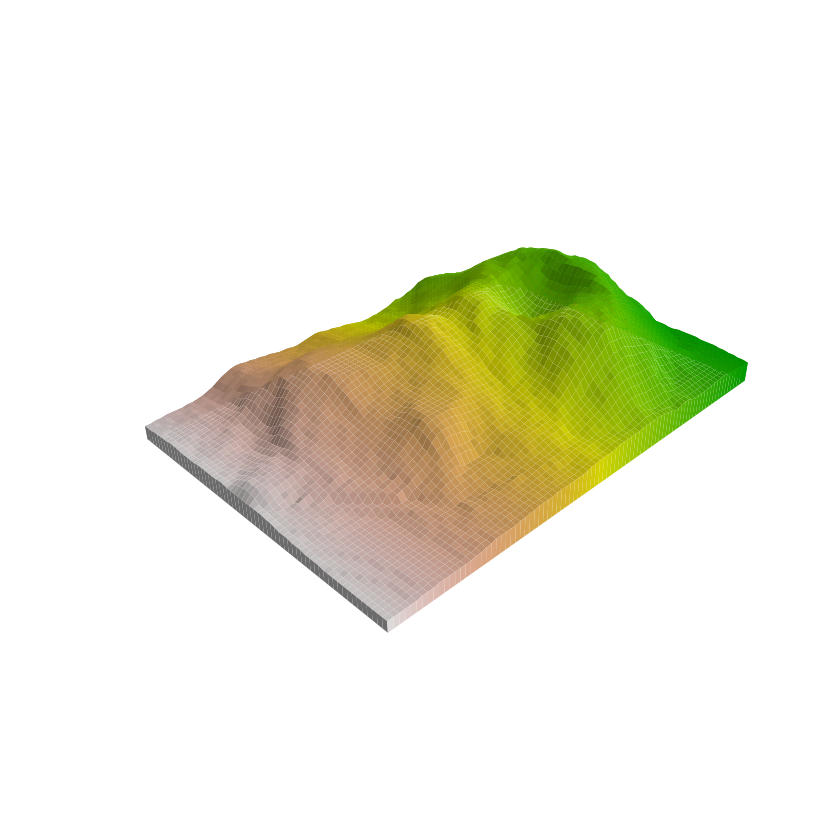


> ## reset par():
> par(oldpar)


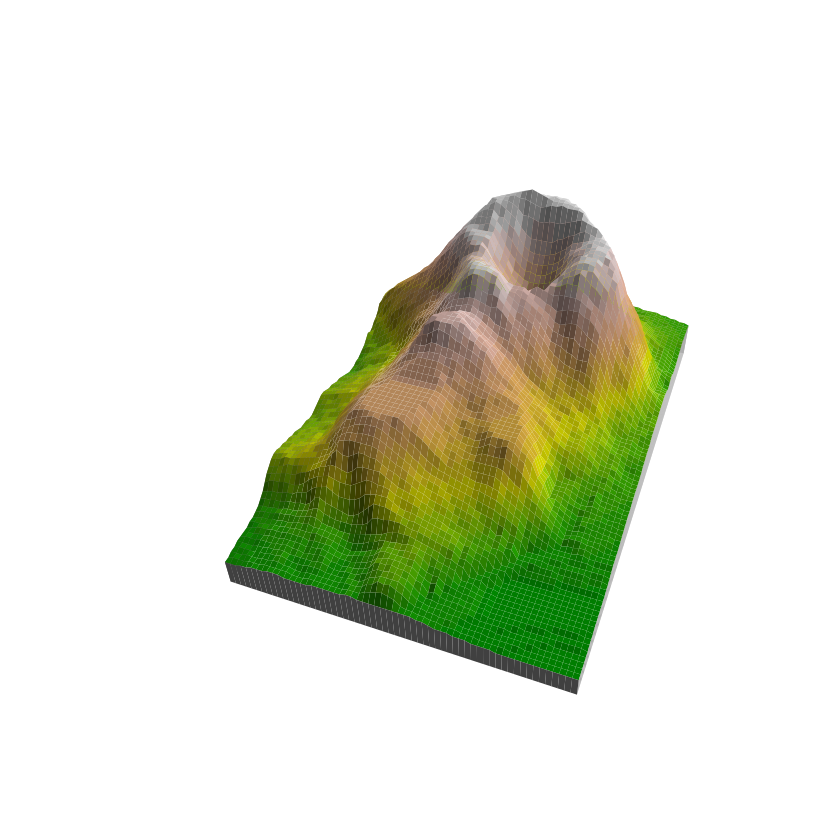

In [8]:
demo(persp)

`demo(graphics)` demonstrates a wider range of R's base graphics capabilities.



	demo(graphics)
	---- ~~~~~~~~

> #  Copyright (C) 1997-2009 The R Core Team
> 
> require(datasets)

> require(grDevices); require(graphics)

> ## Here is some code which illustrates some of the differences between
> ## R and S graphics capabilities.  Note that colors are generally specified
> ## by a character string name (taken from the X11 rgb.txt file) and that line
> ## textures are given similarly.  The parameter "bg" sets the background
> ## parameter for the plot and there is also an "fg" parameter which sets
> ## the foreground color.
> 
> 
> x <- stats::rnorm(50)

> opar <- par(bg = "white")

> plot(x, ann = FALSE, type = "n")

> abline(h = 0, col = gray(.90))

> lines(x, col = "green4", lty = "dotted")

> points(x, bg = "limegreen", pch = 21)

> title(main = "Simple Use of Color In a Plot",
+       xlab = "Just a Whisper of a Label",
+       col.main = "blue", col.lab = gray(.8),
+       cex.main = 1.2, cex.lab = 1.0, font.main = 4, font.lab = 3)

> ## A little color wheel

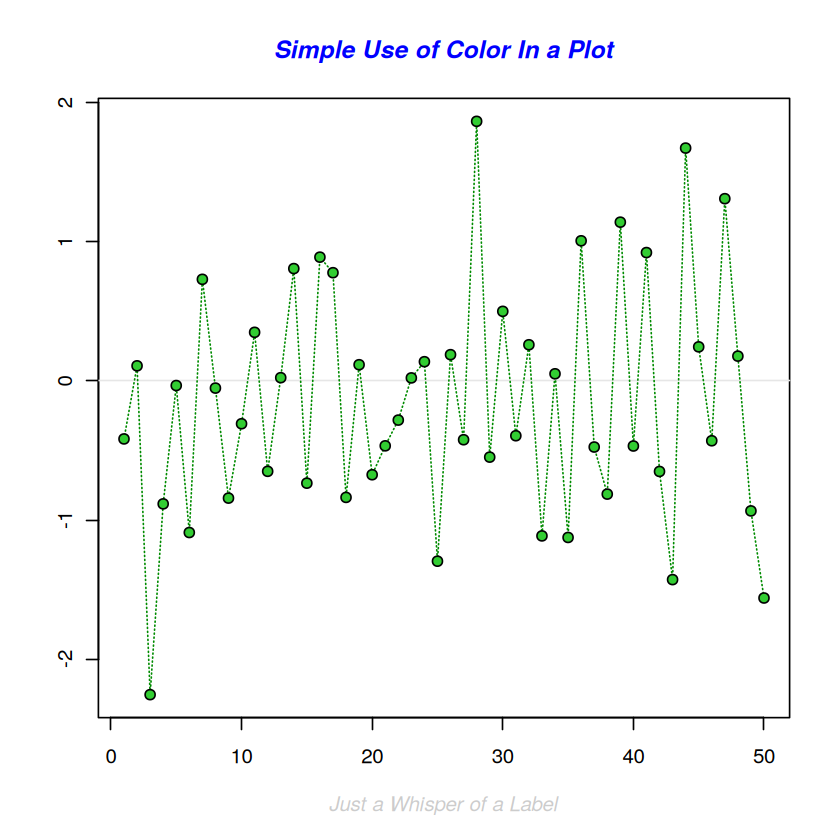


> title(main = "A Sample Color Wheel", cex.main = 1.4, font.main = 3)

> title(xlab = "(Use this as a test of monitor linearity)",
+       cex.lab = 0.8, font.lab = 3)

> ## We have already confessed to having these.  This is just showing off X11
> ## color names (and the example (from the postscript manual) is pretty "cute".
> 
> pie.sales <- c(0.12, 0.3, 0.26, 0.16, 0.04, 0.12)

> names(pie.sales) <- c("Blueberry", "Cherry",
+ 		      "Apple", "Boston Cream", "Other", "Vanilla Cream")

> pie(pie.sales,
+     col = c("purple","violetred1","green3","cornsilk","cyan","white"))


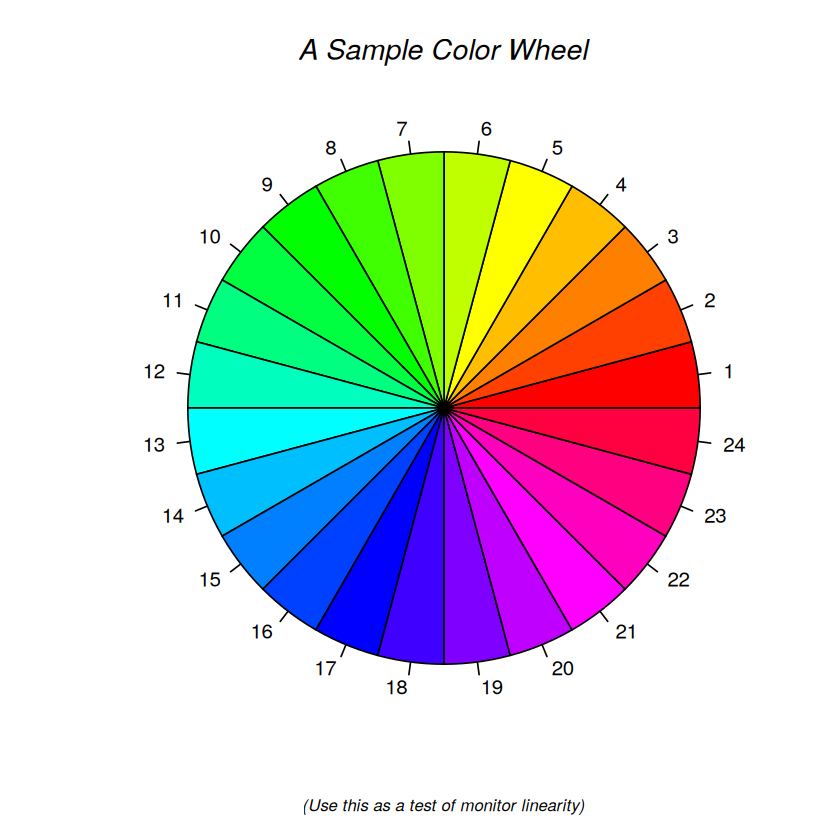


> title(main = "January Pie Sales", cex.main = 1.8, font.main = 1)

> title(xlab = "(Don't try this at home kids)", cex.lab = 0.8, font.lab = 3)

> ## Boxplots:  I couldn't resist the capability for filling the "box".
> ## The use of color seems like a useful addition, it focuses attention
> ## on the central bulk of the data.
> 
> par(bg="cornsilk")

> n <- 10

> g <- gl(n, 100, n*100)

> x <- rnorm(n*100) + sqrt(as.numeric(g))

> boxplot(split(x,g), col="lavender", notch=TRUE)


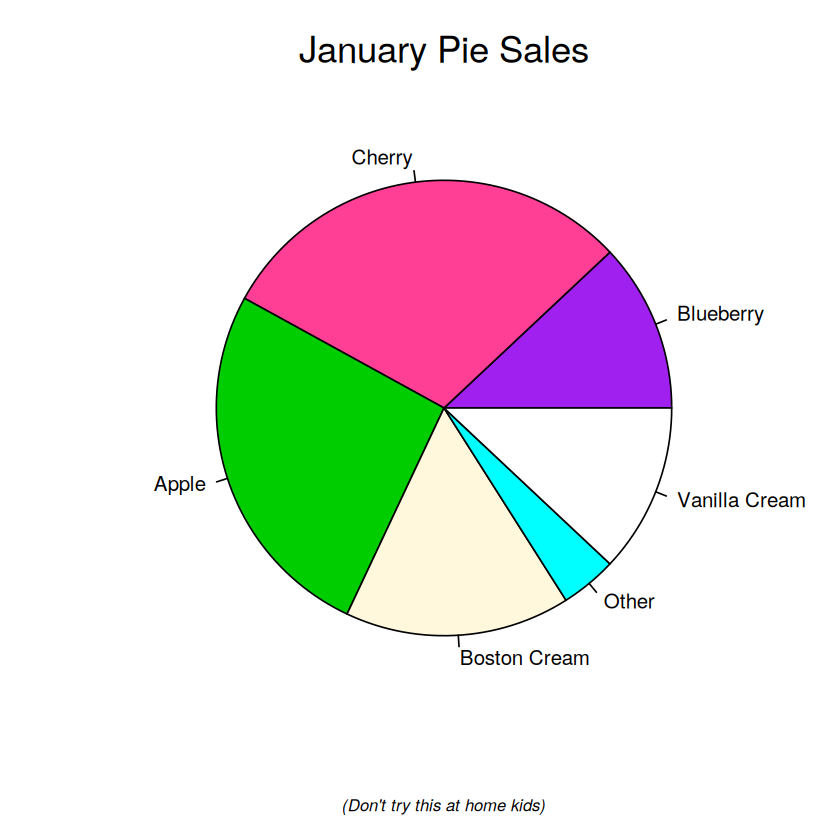


> title(main="Notched Boxplots", xlab="Group", font.main=4, font.lab=1)

> ## An example showing how to fill between curves.
> 
> par(bg="white")

> n <- 100

> x <- c(0,cumsum(rnorm(n)))

> y <- c(0,cumsum(rnorm(n)))

> xx <- c(0:n, n:0)

> yy <- c(x, rev(y))

> plot(xx, yy, type="n", xlab="Time", ylab="Distance")


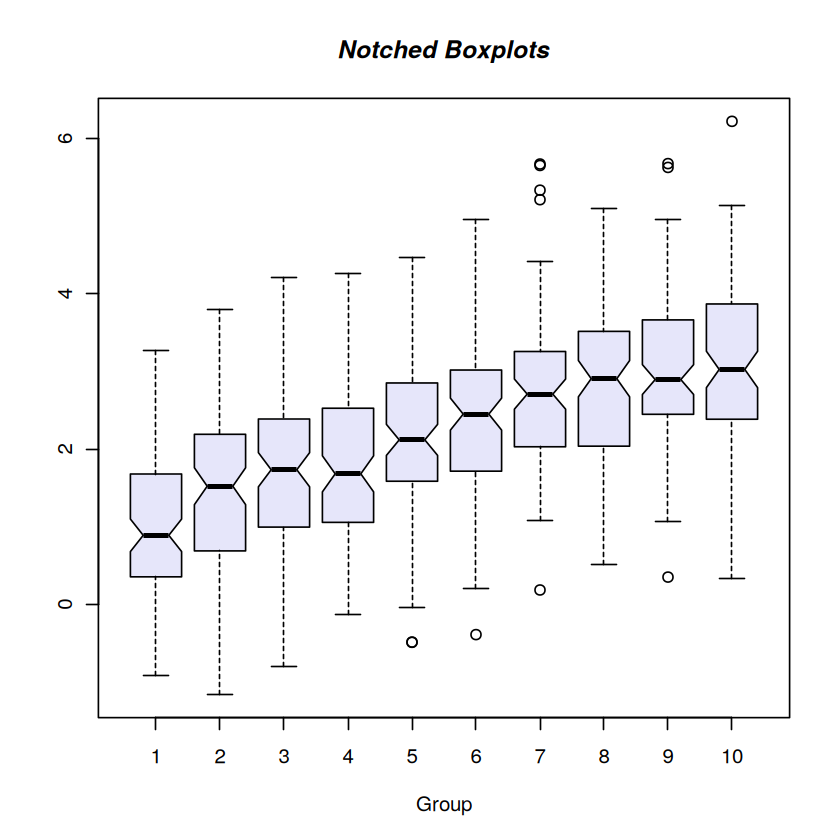


> polygon(xx, yy, col="gray")

> title("Distance Between Brownian Motions")

> ## Colored plot margins, axis labels and titles.	 You do need to be
> ## careful with these kinds of effects.	It's easy to go completely
> ## over the top and you can end up with your lunch all over the keyboard.
> ## On the other hand, my market research clients love it.
> 
> x <- c(0.00, 0.40, 0.86, 0.85, 0.69, 0.48, 0.54, 1.09, 1.11, 1.73, 2.05, 2.02)

> par(bg="lightgray")

> plot(x, type="n", axes=FALSE, ann=FALSE)


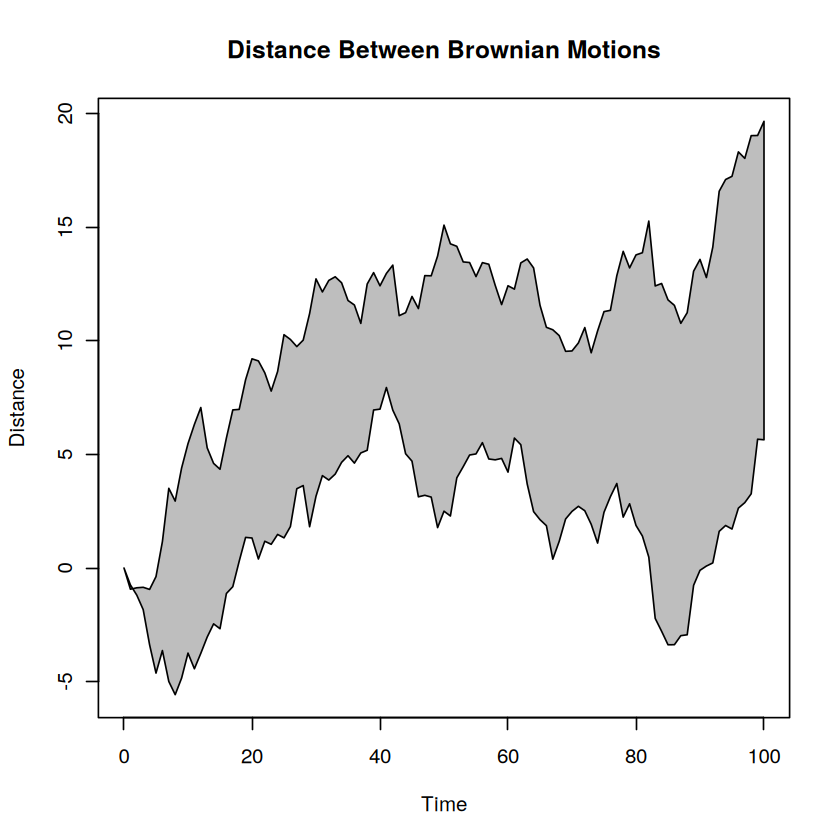


> usr <- par("usr")

> rect(usr[1], usr[3], usr[2], usr[4], col="cornsilk", border="black")

> lines(x, col="blue")

> points(x, pch=21, bg="lightcyan", cex=1.25)

> axis(2, col.axis="blue", las=1)

> axis(1, at=1:12, lab=month.abb, col.axis="blue")

> box()

> title(main= "The Level of Interest in R", font.main=4, col.main="red")

> title(xlab= "1996", col.lab="red")

> ## A filled histogram, showing how to change the font used for the
> ## main title without changing the other annotation.
> 
> par(bg="cornsilk")

> x <- rnorm(1000)

> hist(x, xlim=range(-4, 4, x), col="lavender", main="")


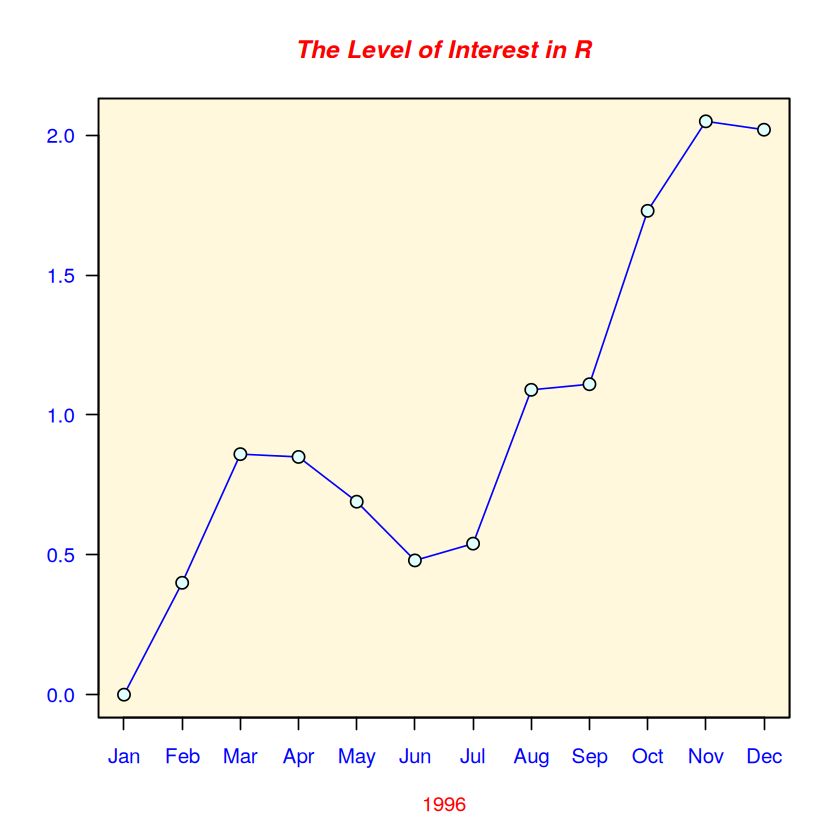


> title(main="1000 Normal Random Variates", font.main=3)

> ## A scatterplot matrix
> ## The good old Iris data (yet again)
> 
> pairs(iris[1:4], main="Edgar Anderson's Iris Data", font.main=4, pch=19)


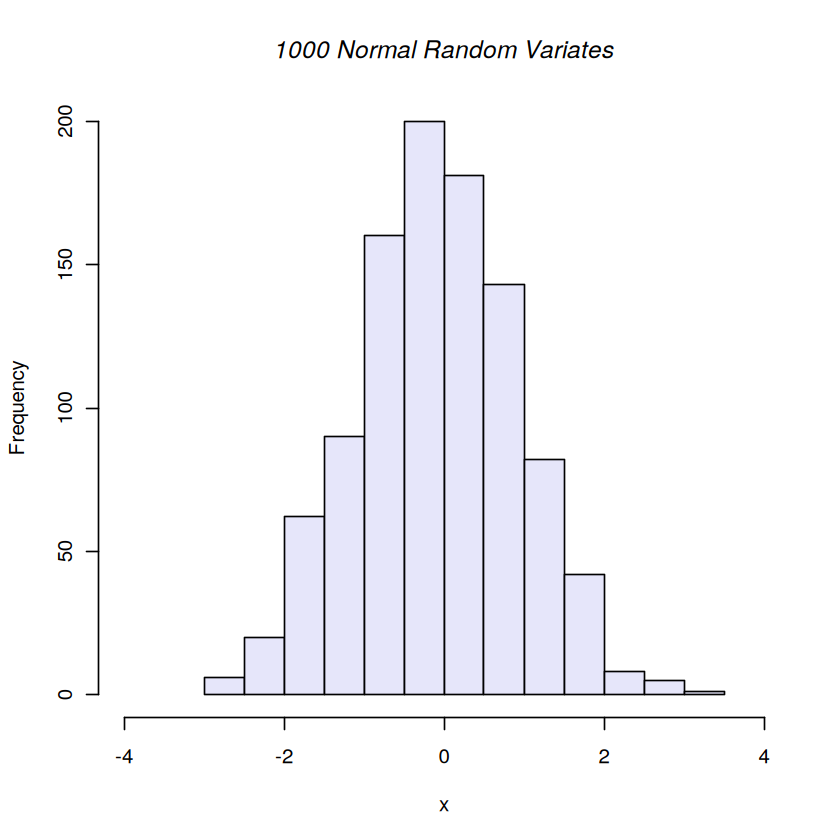


> pairs(iris[1:4], main="Edgar Anderson's Iris Data", pch=21,
+       bg = c("red", "green3", "blue")[unclass(iris$Species)])


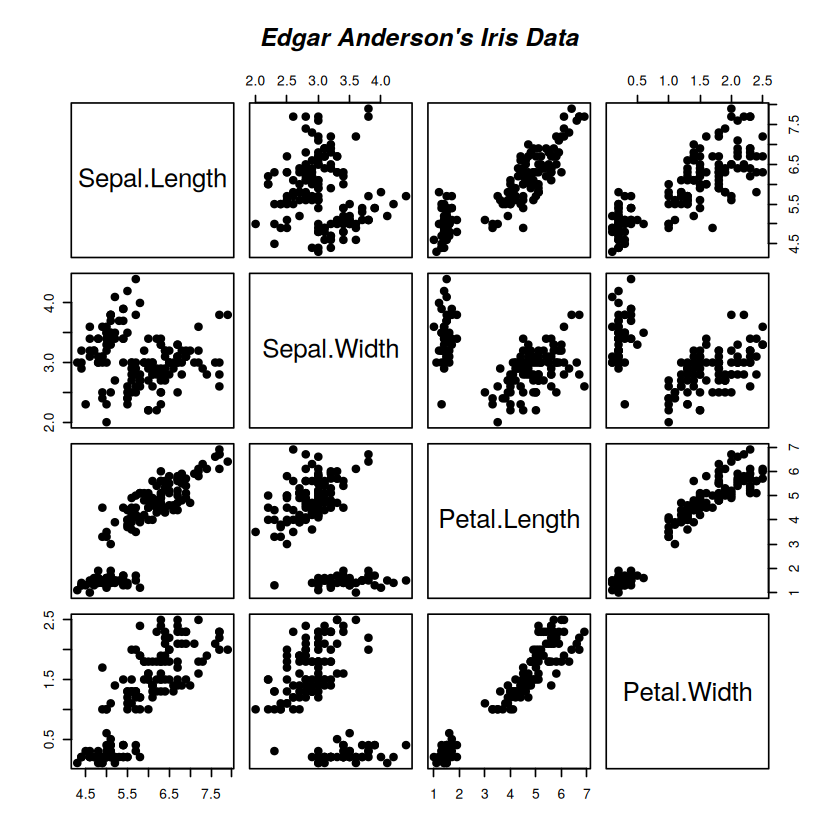


> ## Contour plotting
> ## This produces a topographic map of one of Auckland's many volcanic "peaks".
> 
> x <- 10*1:nrow(volcano)

> y <- 10*1:ncol(volcano)

> lev <- pretty(range(volcano), 10)

> par(bg = "lightcyan")

> pin <- par("pin")

> xdelta <- diff(range(x))

> ydelta <- diff(range(y))

> xscale <- pin[1]/xdelta

> yscale <- pin[2]/ydelta

> scale <- min(xscale, yscale)

> xadd <- 0.5*(pin[1]/scale - xdelta)

> yadd <- 0.5*(pin[2]/scale - ydelta)

> plot(numeric(0), numeric(0),
+      xlim = range(x)+c(-1,1)*xadd, ylim = range(y)+c(-1,1)*yadd,
+      type = "n", ann = FALSE)


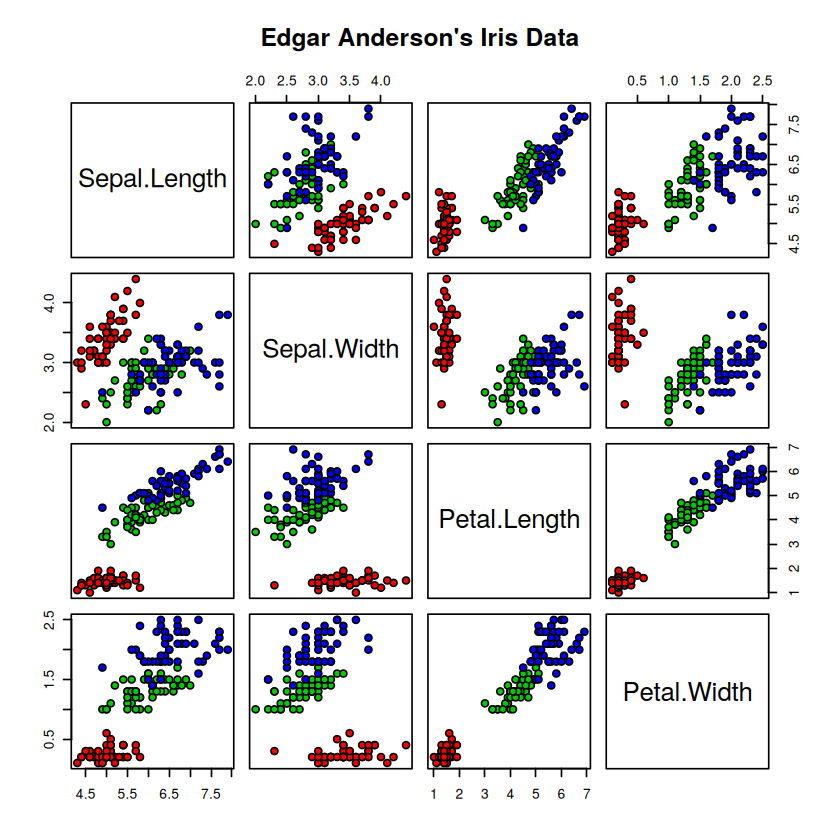


> usr <- par("usr")

> rect(usr[1], usr[3], usr[2], usr[4], col="green3")

> contour(x, y, volcano, levels = lev, col="yellow", lty="solid", add=TRUE)

> box()

> title("A Topographic Map of Maunga Whau", font= 4)

> title(xlab = "Meters North", ylab = "Meters West", font= 3)

> mtext("10 Meter Contour Spacing", side=3, line=0.35, outer=FALSE,
+       at = mean(par("usr")[1:2]), cex=0.7, font=3)

> ## Conditioning plots
> 
> par(bg="cornsilk")

> coplot(lat ~ long | depth, data = quakes, pch = 21, bg = "green3")


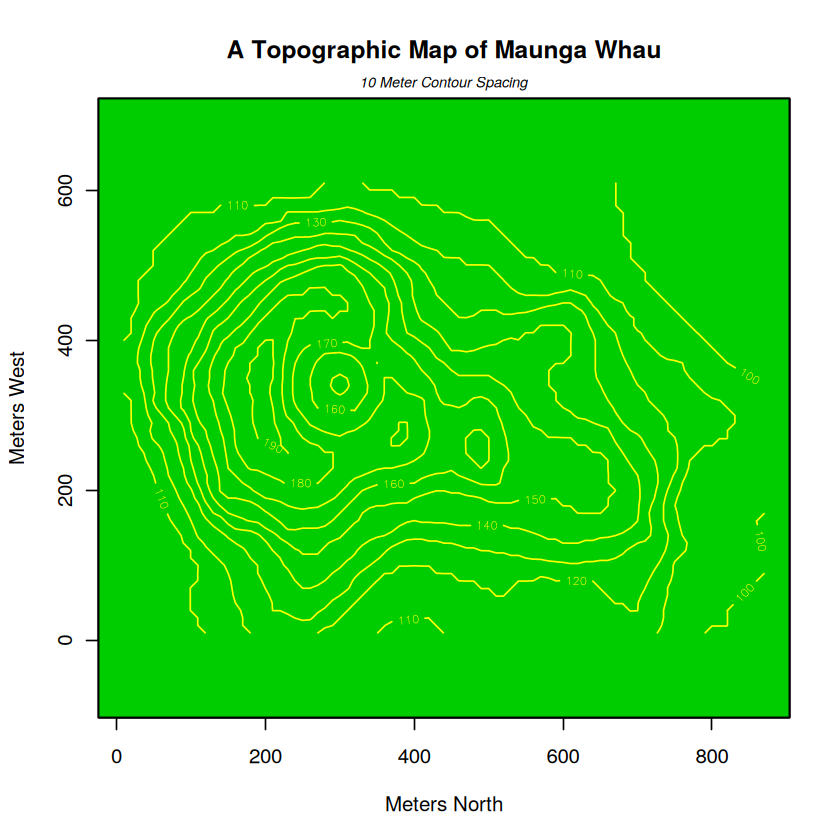


> par(opar)


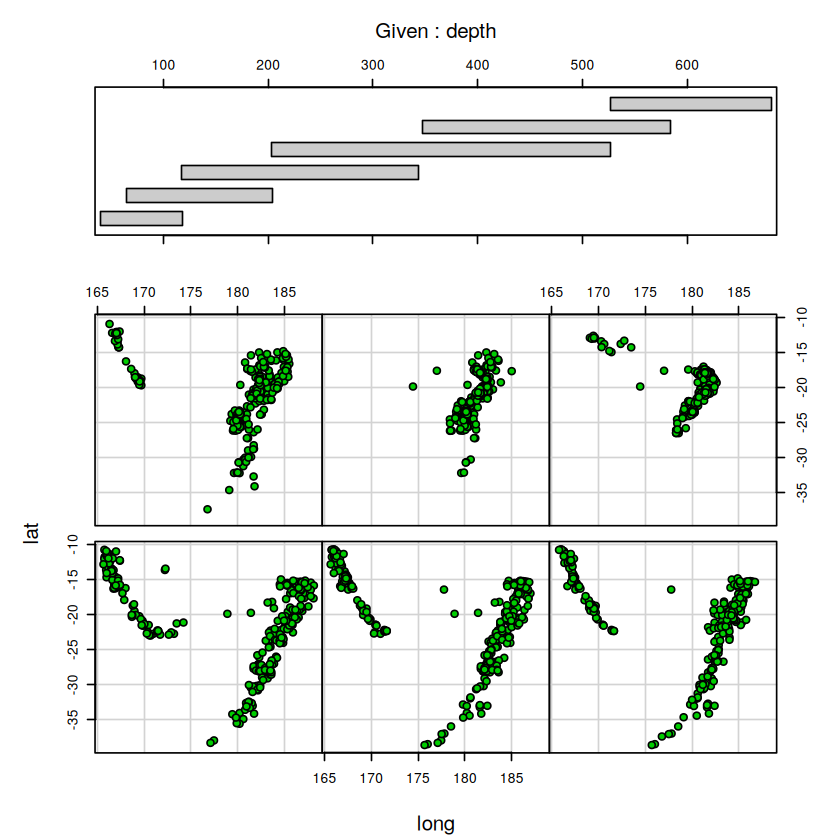

In [9]:
demo(graphics)

## Lecture 3 — Introduction: Packages and Libraries in R

**What is a library?** A library is a collection of books or media that is easily accessible for use, not just for display — a person finds a suitable item, gets it issued, uses it, and returns it when done.

**Libraries in R.** R packages are collections of programs and data sets developed by different users and scientists; they extend R's functionality. Commonly used functions are added to base R, but not everything can be — the base package would become too large, and not everyone wants every feature. For example, someone interested in cluster analysis won't find it in base R, but the `cluster` package (built by experts) can be downloaded and used for free whenever it's needed.

To use a library, call `library()` with the library's name in brackets — the notes show the generic syntax `library(.)` and the concrete example `library(spatial)`.

In [10]:
library(spatial)

There are two types of libraries in R: some ship as part of the base package (the notes give `MASS` — associated with Venables & Ripley's *Modern Applied Statistics using S-Plus* — and `mgcv`, for generalized additive models, as examples), and others are user-dependent, installed only when needed (the notes give `spatial`, for spatial analysis, and `boot`, for the bootstrap, as examples — though in this environment, as in the notes' own later screenshots, `spatial` is in fact installed and loads above without error, since it ships as a *recommended* package with R itself).

### Description of Libraries

`packageDescription()` shows a package's description file.

In [11]:
packageDescription("spatial")

Package: spatial
Priority: recommended
Version: 7.3-17
Date: 2023-07-20
Depends: R (>= 3.0.0), graphics, stats, utils
Suggests: MASS
Authors@R: c(person("Brian", "Ripley", role = c("aut", "cre", "cph"),
        email = "ripley@stats.ox.ac.uk"), person("Roger", "Bivand",
        role = "ctb"), person("William", "Venables", role = "cph"))
Description: Functions for kriging and point pattern analysis.
Title: Functions for Kriging and Point Pattern Analysis
LazyLoad: yes
ByteCompile: yes
License: GPL-2 | GPL-3
URL: http://www.stats.ox.ac.uk/pub/MASS4/
NeedsCompilation: yes
Packaged: 2023-07-20 14:41:40 UTC; ripley
Author: Brian Ripley [aut, cre, cph], Roger Bivand [ctb], William
        Venables [cph]
Maintainer: Brian Ripley <ripley@stats.ox.ac.uk>
Repository: CRAN
Date/Publication: 2023-07-20 15:08:46 UTC
Built: R 4.3.3; x86_64-pc-linux-gnu; 'Mon, 22 Apr 2024 13:11:30 +0200';
        unix

-- File: /usr/lib/R/library/spatial/Meta/package.rds 

### Contents of Libraries

`library(help = packagename)` lists the functions and data sets in a package.

In [12]:
library(help=spatial)

### Installing Packages and Libraries

The base R package contains programs for basic operations, but not every library needed for advanced statistical work. Specific requirements are met by downloading special packages, which is done with `install.packages()`.

In [13]:
install.packages("boot")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message:
“unable to access index for repository https://cloud.r-project.org/src/contrib:
  cannot open URL 'https://cloud.r-project.org/src/contrib/PACKAGES'”
Warning message:
“package ‘boot’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-patched/R-admin.html#Installing-packages”


In [14]:
install.packages("cluster")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message:
“unable to access index for repository https://cloud.r-project.org/src/contrib:
  cannot open URL 'https://cloud.r-project.org/src/contrib/PACKAGES'”
Warning message:
“package ‘cluster’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-patched/R-admin.html#Installing-packages”


> **Note on this environment:** the notes' screenshots show `install.packages()` successfully downloading each package from a CRAN mirror. This sandboxed environment has no outbound network access to CRAN, so both calls above run for real but fail to reach the repository — a genuine difference in *network availability*, not a different command or a fabricated result. (Both `boot` and `cluster` are, in fact, already installed in this environment as recommended packages, as the next cell shows.)

### Which Packages Are Installed on My Computer

`installed.packages()` lists every installed package, its library path, and its version.

In [15]:
head(installed.packages(), 10)

,Package,LibPath,Version,Priority,Depends,Imports,LinkingTo,Suggests,Enhances,License,License_is_FOSS,License_restricts_use,OS_type,MD5sum,NeedsCompilation,Built
AER,AER,/usr/lib/R/site-library,1.2-12,NA,"R (>= 3.0.0), car (>= 2.0-19), lmtest, sandwich (>= 2.4-0), survival (>= 2.37-5), zoo","stats, Formula (>= 0.2-0)",NA,"boot, dynlm, effects, fGarch, forecast, foreign, ineq, KernSmooth, lattice, longmemo, MASS, mlogit, nlme, nnet, np, plm, pscl, quantreg, rgl, ROCR, rugarch, sampleSelection, scatterplot3d, strucchange, systemfit (>= 1.1-20), truncreg, tseries, urca, vars",NA,GPL-2 | GPL-3,NA,NA,NA,NA,no,4.3.2
Amelia,Amelia,/usr/lib/R/site-library,1.8.1,NA,"R (>= 3.0.2), Rcpp (>= 0.11)","foreign, utils, grDevices, graphics, methods, stats, rlang","Rcpp (>= 0.11), RcppArmadillo","tcltk, broom, rmarkdown, knitr",NA,GPL (>= 2),NA,NA,NA,NA,yes,4.3.0
BH,BH,/usr/lib/R/site-library,1.84.0,NA,NA,NA,NA,NA,NA,GPL (>= 2),NA,NA,NA,NA,NA,4.3.2
BayesFM,BayesFM,/usr/lib/R/site-library,0.1.5,NA,R (>= 3.0.0),"checkmate (>= 1.8.0), coda, ggplot2 (>= 2.1.0), gridExtra, plyr (>= 1.8.0)",NA,NA,NA,GPL-3,NA,NA,NA,NA,yes,4.3.1
BayesFactor,BayesFactor,/usr/lib/R/site-library,0.9.12-4.7,NA,"R (>= 3.2.0), coda, Matrix (>= 1.1-1)","pbapply, mvtnorm, stringr, utils, graphics, MatrixModels, Rcpp (>= 0.11.2), methods, hypergeo","Rcpp (>= 0.11.2), RcppEigen (>= 0.3.2.2.0)","doMC, foreach, testthat, knitr, markdown, rmarkdown, arm, lme4, xtable, languageR",NA,GPL-2,NA,NA,NA,NA,yes,4.3.2
BiasedUrn,BiasedUrn,/usr/lib/R/site-library,2.0.11,NA,NA,NA,NA,NA,NA,GPL-3,NA,NA,NA,NA,yes,4.3.1
Biobase,Biobase,/usr/lib/R/site-library,2.62.0,NA,"R (>= 2.10), BiocGenerics (>= 0.27.1), utils",methods,NA,"tools, tkWidgets, ALL, RUnit, golubEsets, BiocStyle, knitr",NA,Artistic-2.0,NA,NA,NA,NA,yes,4.3.2
BiocGenerics,BiocGenerics,/usr/lib/R/site-library,0.48.1,NA,"R (>= 4.0.0), methods, utils, graphics, stats","methods, utils, graphics, stats",NA,"Biobase, S4Vectors, IRanges, GenomicRanges, DelayedArray, Biostrings, Rsamtools, AnnotationDbi, affy, affyPLM, DESeq2, flowClust, MSnbase, annotate, RUnit",NA,Artistic-2.0,NA,NA,NA,NA,no,4.3.2
BiocManager,BiocManager,/usr/lib/R/site-library,1.30.22,NA,NA,utils,NA,"BiocVersion, remotes, rmarkdown, testthat, withr, curl, knitr",NA,Artistic-2.0,NA,NA,NA,NA,no,4.3.1
BiocVersion,BiocVersion,/usr/lib/R/site-library,3.18.1,NA,R (>= 4.3.0),NA,NA,NA,NA,Artistic-2.0,NA,NA,NA,NA,no,4.3.2


> **Note on display:** the notes' own screenshot of `installed.packages()` is itself truncated (it ends in "… …" after six rows). Run bare, `installed.packages()` in this environment returns a real, verified 514-row matrix — far more than the ~10-package Windows R 4.1.2 install the notes were recorded on, simply because this Linux container ships a larger set of recommended/base packages by default. Showing the bare command in full would be over a thousand lines of near-identical text, so, in the same spirit as the notes' own truncated screenshot, `head(..., 10)` is used here to show the first 10 real rows rather than reproducing the entire matrix.

### Uninstalling Packages Installed on My Computer

`remove.packages("package")` removes an installed package.

In [16]:
mylib = file.path(tempdir(), "demo_Rlib")
dir.create(mylib, showWarnings = FALSE)
file.copy(system.file(package = "cluster"), mylib, recursive = TRUE)
.libPaths(c(mylib, .libPaths()))

[1] TRUE

> **Note on the cell above:** `remove.packages()` permanently deletes the named package from disk. To demonstrate the exact command from the notes, `remove.packages("cluster")`, honestly — with real, executed output — without permanently deleting `cluster` from this shared environment (which every other command and every other week's notebook also relies on), the three lines above first copy `cluster` into a personal, throwaway library folder and place that folder first on `.libPaths()`. Since `remove.packages()` defaults to removing from `.libPaths()[1]` when no `lib` argument is given, the bare command below — identical to the notes — now safely removes only that throwaway copy.

In [17]:
remove.packages("cluster")

Removing package from ‘/tmp/RtmpcflvwU/demo_Rlib’
(as ‘lib’ is unspecified)



### Updating Packages Installed on My Computer

`update.packages()` checks for and installs newer versions of installed packages.

In [18]:
update.packages("cluster")

Warning message:
“unable to access index for repository https://cloud.r-project.org/src/contrib:
  cannot open URL 'https://cloud.r-project.org/src/contrib/PACKAGES'”


> **Note on this environment:** as with `install.packages()` above, this real command fails to reach CRAN because the sandbox has no outbound access to it — a genuine network-availability difference from the notes, not a different command.

### Unloading Packages Installed on My Computer

`detach("package:name", unload = TRUE)` unloads an attached package. The notes show this being called twice: the first call succeeds (after `library(cluster)` attaches it), and the second call — run again with nothing left attached — fails with `invalid 'name' argument`.

In [19]:
library(cluster)
detach("package:cluster", unload=TRUE)

> **Note on the cell below:** calling `detach("package:cluster", unload = TRUE)` a second time, with the package no longer attached, raises a real R error (`invalid 'name' argument`) — exactly as the notes' own console screenshot shows. Left unwrapped, that error would halt the rest of this notebook's execution (Jupyter stops at the first uncaught error), so, exactly as was done for a genuine R-version difference in the Week 4 notebook, the call is wrapped in `tryCatch()` here so the real error object is still shown rather than hidden or faked.

In [20]:
tryCatch(
  detach("package:cluster", unload=TRUE),
  error = function(e) e
)

<simpleError in detach("package:cluster", unload = TRUE): invalid 'name' argument>

## Lecture 4 — Introduction: Command Line and Data Editor

**Command Line versus Scripts.** R's execution is not menu-driven — there's no clicking buttons to get an outcome. Commands must be typed, either as single lines or multi-line programs, and for multi-line work it helps to use a text editor rather than typing everything directly at the command line.

**Option 1 — R's own built-in editor.** From the RGui menu bar: `File` → `New script` opens an `Untitled - R Editor` window to type and edit in. Highlighting a line (or group of lines) and pressing `Ctrl+R` executes just that selection.

**Option 2 — another editor.** Dedicated editors such as R Studio or Tinn R (free software) can also drive R. R Studio is a free, open-source IDE for R, written in C++, downloaded from `https://www.rstudio.com/` (Products → RStudio Desktop → Free). Tinn R is available at `https://sourceforge.net/projects/tinn-r`. In R Studio: commands are typed in the script pane, defined variables appear in the Environment pane, and the familiar R console sits at the bottom.

*(Like Lecture 1, this lecture is entirely about tooling and installation — menus, downloads, and editor windows — and contains no R console commands to execute.)*
